# Notebook 4 : Monte Carlo, Margrabe et Kirk

Le call sur spread se calcule pour l'instant avec trois méthodes, toutes dans le même modèle (GBM bivarié) :

- Monte Carlo (MC) : marche pour tout $K$, mais il est lent et donne un prix avec un peu de bruit ;
- Margrabe : formule exacte, très rapide, mais seulement quand $K = 0$ ;
- Kirk : formule approchée, aussi rapide que Margrabe, pour tout $K$.

Sections 1 à 4 : à $K = 0$, MC et Margrabe doivent donner la même chose (prix, deltas, temps, couverture). Sections 5 à 8 : à $K \neq 0$, de combien Kirk se trompe-t-il par rapport au MC (prix, puis deltas), quand peut-on s'en servir, et la couverture avec ses deltas marche-t-elle ?

Cas de base : Brent 80 \$, WTI 75 \$, $\sigma_1 = 30$ %, $\sigma_2 = 35$ %, $\rho = 0{,}6$, $r = 3$ %, 1 an.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

from spread_options.analytics import kirk_call, kirk_deltas, margrabe_call, margrabe_deltas
from spread_options.monte_carlo import mc_spread_call, mc_spread_deltas
from spread_options.models import simulate_bivariate_gbm_paths
from spread_options.hedging import delta_hedge_spread_pnl
from spread_options.products import spread_call_payoff

S1_0, S2_0 = 80.0, 75.0
sigma1, sigma2, rho = 0.30, 0.35, 0.6
r, T = 0.03, 1.0

# figure style: thin recessive grid, no top/right frame, the same 3 colours everywhere
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.edgecolor": "#8a8984",
                     "lines.linewidth": 2, "lines.markersize": 7, "figure.dpi": 110,
                     "axes.titleweight": "bold", "axes.titlesize": 11, "legend.frameon": False, "axes.axisbelow": True})

## 1. Le prix à $K = 0$

Si les deux méthodes sont justes, l'écart entre elles doit rester petit devant l'erreur standard du MC (moins de 3 erreurs standard). On le vérifie pour trois valeurs de $\rho$.

rho = 0.6: Margrabe 11.776 $, MC 11.687 $ +/- 0.047, écart = -1.9 erreurs standard
rho = 0.85: Margrabe 8.537 $, MC 8.490 $ +/- 0.031, écart = -1.5 erreurs standard
rho = 0.97: Margrabe 6.059 $, MC 6.055 $ +/- 0.016, écart = -0.2 erreurs standard


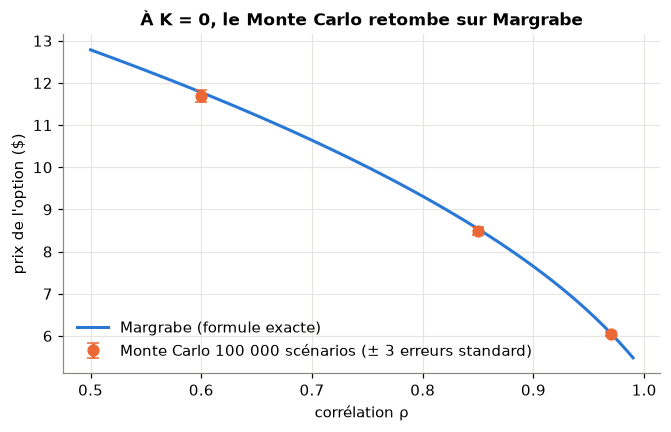

In [2]:
rhos_k0 = [0.6, 0.85, 0.97]
mc_k0, err_k0 = [], []
for rho_test in rhos_k0:
    exact = margrabe_call(S1_0, S2_0, T, sigma1, sigma2, rho_test)
    mc, err = mc_spread_call(S1_0, S2_0, 0.0, T, r, sigma1, sigma2, rho_test)
    mc_k0.append(mc)
    err_k0.append(err)
    print(f"rho = {rho_test}: Margrabe {exact:.3f} $, MC {mc:.3f} $ +/- {err:.3f}, "
          f"écart = {(mc - exact) / err:+.1f} erreurs standard")

rho_grid = np.linspace(0.5, 0.99, 100)  # Margrabe is instant: draw it as a full curve
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(rho_grid, [margrabe_call(S1_0, S2_0, T, sigma1, sigma2, x) for x in rho_grid], color=BLUE, label="Margrabe (formule exacte)")
ax.errorbar(rhos_k0, mc_k0, yerr=3 * np.array(err_k0), fmt="o", color=ORANGE, capsize=4,
            label="Monte Carlo 100 000 scénarios (± 3 erreurs standard)")
ax.set_xlabel("corrélation ρ")
ax.set_ylabel("prix de l'option ($)")
ax.set_title("À K = 0, le Monte Carlo retombe sur Margrabe")
ax.legend()
plt.show()

## 2. Les deltas à $K = 0$

Même vérification pour les deltas (nombre de barils de Brent et de WTI à détenir). Côté MC, on utilise `mc_spread_deltas` (méthode pathwise). La figure montre en plus ce qui se passe quand on augmente le nombre de scénarios : le bruit du MC se resserre autour de Margrabe.

delta Brent : Margrabe +0.6430, MC +0.6426 +/- 0.0018
delta WTI   : Margrabe -0.5289, MC -0.5296 +/- 0.0015


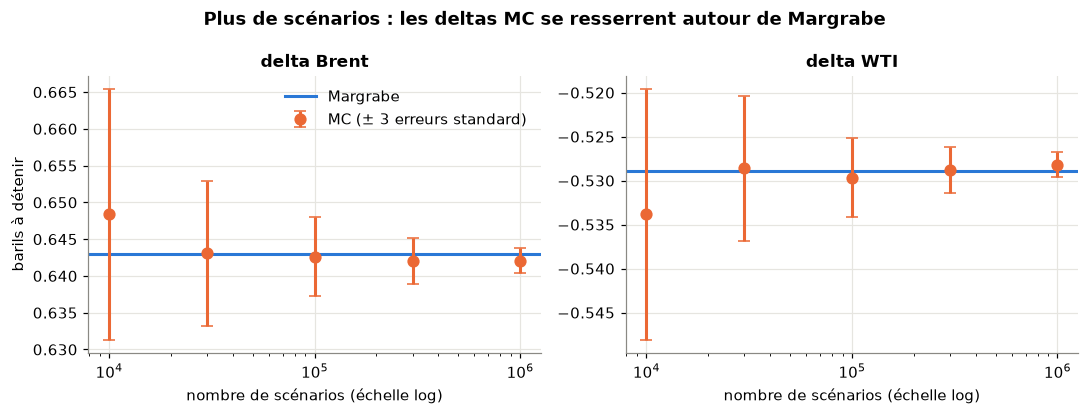

In [3]:
exact1, exact2 = margrabe_deltas(S1_0, S2_0, T, sigma1, sigma2, rho)
mc1, mc2, err1, err2 = mc_spread_deltas(S1_0, S2_0, 0.0, T, r, sigma1, sigma2, rho)
print(f"delta Brent : Margrabe {exact1:+.4f}, MC {mc1:+.4f} +/- {err1:.4f}")
print(f"delta WTI   : Margrabe {exact2:+.4f}, MC {mc2:+.4f} +/- {err2:.4f}")

n_list = [10_000, 30_000, 100_000, 300_000, 1_000_000]
conv = [mc_spread_deltas(S1_0, S2_0, 0.0, T, r, sigma1, sigma2, rho, n_paths=n) for n in n_list]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, k, exact, name in [(axes[0], 0, exact1, "delta Brent"), (axes[1], 1, exact2, "delta WTI")]:
    ax.axhline(exact, color=BLUE, label="Margrabe")
    ax.errorbar(n_list, [c[k] for c in conv], yerr=[3 * c[k + 2] for c in conv], fmt="o", color=ORANGE,
                capsize=4, label="MC (± 3 erreurs standard)")  # c = (delta1, delta2, err1, err2)
    ax.set_xscale("log")
    ax.set_xlabel("nombre de scénarios (échelle log)")
    ax.set_title(name)
axes[0].set_ylabel("barils à détenir")
axes[0].legend()
fig.suptitle("Plus de scénarios : les deltas MC se resserrent autour de Margrabe", fontweight="bold")
plt.tight_layout()
plt.show()

## 3. Le temps de calcul

On chronomètre un prix, en faisant la moyenne sur plusieurs appels. Kirk est chronométré à $K = 5$.

MC       : 4.41 ms par prix
Margrabe : 0.077 ms par prix (58 fois plus rapide que le MC)
Kirk     : 0.078 ms par prix (57 fois plus rapide que le MC)


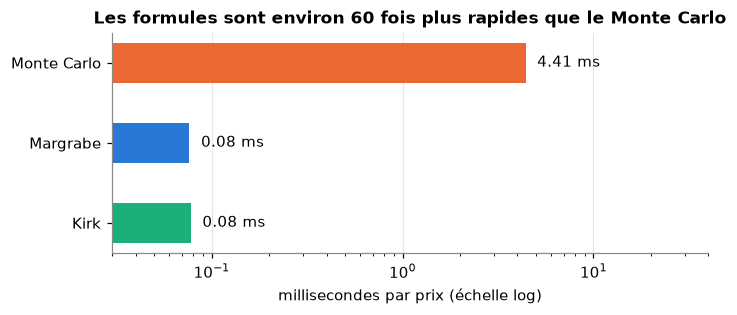

In [4]:
def time_ms(fn, n_calls):
    start = time.perf_counter()
    for _ in range(n_calls):
        fn()
    return (time.perf_counter() - start) / n_calls * 1000  # milliseconds per call

t_mc = time_ms(lambda: mc_spread_call(S1_0, S2_0, 0.0, T, r, sigma1, sigma2, rho), 20)
t_margrabe = time_ms(lambda: margrabe_call(S1_0, S2_0, T, sigma1, sigma2, rho), 2000)
t_kirk = time_ms(lambda: kirk_call(S1_0, S2_0, 5.0, T, r, sigma1, sigma2, rho), 2000)
print(f"MC       : {t_mc:.2f} ms par prix")
print(f"Margrabe : {t_margrabe:.3f} ms par prix ({t_mc / t_margrabe:.0f} fois plus rapide que le MC)")
print(f"Kirk     : {t_kirk:.3f} ms par prix ({t_mc / t_kirk:.0f} fois plus rapide que le MC)")

fig, ax = plt.subplots(figsize=(7, 2.6))
names, times = ["Monte Carlo", "Margrabe", "Kirk"], [t_mc, t_margrabe, t_kirk]
ax.barh(names, times, color=[ORANGE, BLUE, AQUA], height=0.5)
for y, t in enumerate(times):
    ax.text(t * 1.15, y, f"{t:.2f} ms", va="center")  # value written next to its bar
ax.set_xscale("log")
ax.set_xlim(0.03, 40)
ax.invert_yaxis()  # Monte Carlo on top
ax.set_xlabel("millisecondes par prix (échelle log)")
ax.set_title("Les formules sont environ 60 fois plus rapides que le Monte Carlo")
ax.grid(axis="y", visible=False)
plt.show()

## 4. La couverture en simulation (Margrabe)

On vend l'option à $K = 0$ au prix de Margrabe, puis on couvre chaque jour les deux jambes avec les deltas de Margrabe, sur 1000 scénarios simulés. Si la méthode est bonne, le P&L moyen est proche de 0.

prime : 11.78 $
P&L moyen : +0.017 $, écart-type : 0.549 $ (4.7% de la prime)


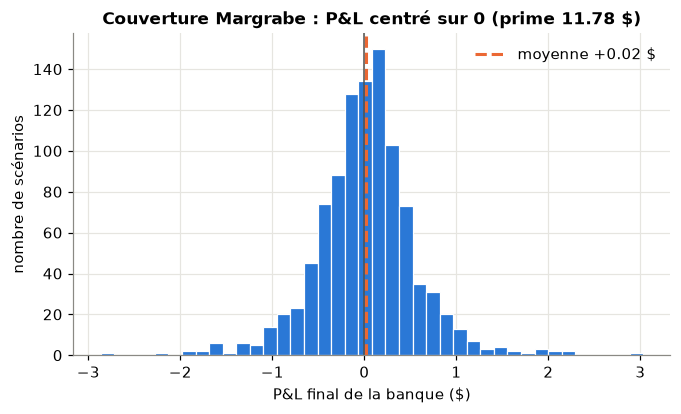

In [5]:
n_steps = 252
obs_times = np.linspace(0, T, n_steps + 1)  # day 0 to day 252
paths1, paths2 = simulate_bivariate_gbm_paths(S1_0, S2_0, r, sigma1, sigma2, rho, obs_times, n_paths=1000)

price0 = margrabe_call(S1_0, S2_0, T, sigma1, sigma2, rho)
pnl = delta_hedge_spread_pnl(
    paths1, paths2, T, r, price0,
    lambda S1, S2, t: margrabe_deltas(S1, S2, t, sigma1, sigma2, rho),
    lambda S1T, S2T: spread_call_payoff(S1T, S2T, 0.0),
)

print(f"prime : {price0:.2f} $")
print(f"P&L moyen : {pnl.mean():+.3f} $, écart-type : {pnl.std():.3f} $ ({pnl.std() / price0:.1%} de la prime)")

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.hist(pnl, bins=40, color=BLUE, edgecolor="white", linewidth=0.8)
ax.axvline(0, color="#52514e", linewidth=1)
ax.axvline(pnl.mean(), color=ORANGE, linestyle="--", label=f"moyenne {pnl.mean():+.2f} $")
ax.set_xlabel("P&L final de la banque ($)")
ax.set_ylabel("nombre de scénarios")
ax.set_title(f"Couverture Margrabe : P&L centré sur 0 (prime {price0:.2f} $)")
ax.legend()
plt.show()

## 5. Kirk quand $K \neq 0$ : l'erreur de prix

Pour $K \neq 0$ il n'y a pas de formule exacte. La référence est donc un MC de 10 millions de scénarios (5 paquets de 2 millions, graines 101 à 105) : son erreur standard est de l'ordre de 0,1 à 0,5 centime.

On fait varier $K$ de −5 à 30 \$ (le spread vaut 5 \$ aujourd'hui) et $\rho$ entre 0,6 et 0,97 (Brent/WTI : 0,85 à 0,97 hors 2020). Le reste est le cas de base. Environ 15 secondes de calcul.

In [6]:
strikes = [-5.0, 0.0, 5.0, 10.0, 20.0, 30.0]
errors_ct, refs = {}, {}  # Kirk error in cents and MC reference prices, one list per rho
for rho_test in [0.6, 0.9, 0.97]:
    errors_ct[rho_test], refs[rho_test] = [], []
    print(f"rho = {rho_test}")
    for K in strikes:
        runs = [mc_spread_call(S1_0, S2_0, K, T, r, sigma1, sigma2, rho_test, n_paths=2_000_000, seed=s)
                for s in range(101, 106)]  # 5 independent runs
        ref = np.mean([p for p, _ in runs])
        kirk = kirk_call(S1_0, S2_0, K, T, r, sigma1, sigma2, rho_test)
        errors_ct[rho_test].append(100 * (kirk - ref))
        refs[rho_test].append(ref)
        print(f"   K = {K:5.1f} | MC {ref:7.4f} $ | Kirk {kirk:7.4f} $ | "
              f"écart {100 * (kirk - ref):+5.2f} centimes ({(kirk - ref) / ref:+.1%} du prix)")

rho = 0.6


   K =  -5.0 | MC 14.9360 $ | Kirk 14.9503 $ | écart +1.43 centimes (+0.1% du prix)


   K =   0.0 | MC 11.7771 $ | Kirk 11.7762 $ | écart -0.09 centimes (-0.0% du prix)


   K =   5.0 | MC  9.0457 $ | Kirk  9.0472 $ | écart +0.16 centimes (+0.0% du prix)


   K =  10.0 | MC  6.7683 $ | Kirk  6.7798 $ | écart +1.14 centimes (+0.2% du prix)


   K =  20.0 | MC  3.5286 $ | Kirk  3.5499 $ | écart +2.12 centimes (+0.6% du prix)


... (9 outputs left out)

   K =   5.0 | MC  2.6954 $ | Kirk  2.6921 $ | écart -0.33 centimes (-0.1% du prix)


   K =  10.0 | MC  0.8055 $ | Kirk  0.8014 $ | écart -0.42 centimes (-0.5% du prix)


   K =  20.0 | MC  0.0295 $ | Kirk  0.0284 $ | écart -0.11 centimes (-3.6% du prix)


   K =  30.0 | MC  0.0007 $ | Kirk  0.0015 $ | écart +0.07 centimes (+97.0% du prix)


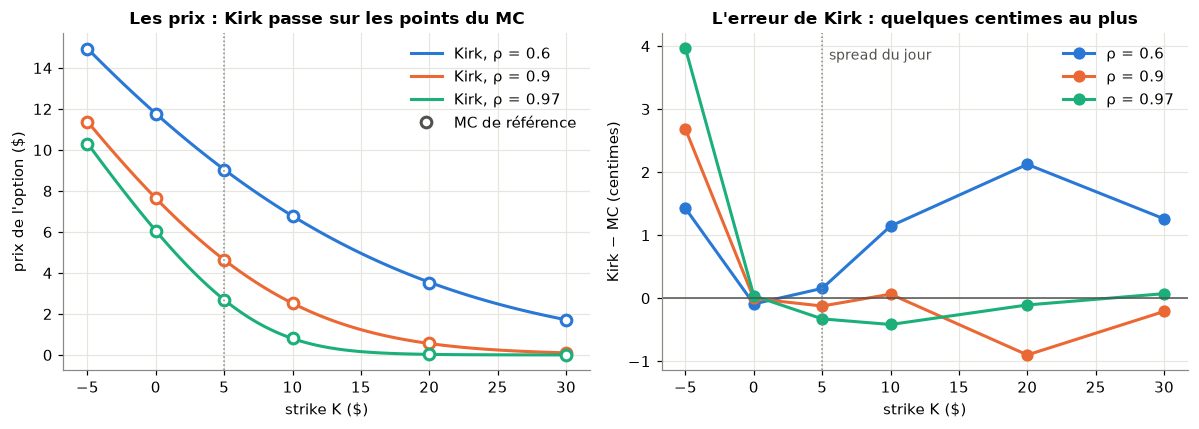

In [7]:
colors = {0.6: BLUE, 0.9: ORANGE, 0.97: AQUA}
K_grid = np.linspace(-5, 30, 100)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for rho_test, c in colors.items():
    # left: Kirk is instant, so a full curve; the expensive MC only on the 6 strikes
    axes[0].plot(K_grid, [kirk_call(S1_0, S2_0, k, T, r, sigma1, sigma2, rho_test) for k in K_grid], color=c,
                 label=f"Kirk, ρ = {rho_test}")
    axes[0].plot(strikes, refs[rho_test], "o", color=c, markerfacecolor="white", markeredgewidth=2)
    axes[1].plot(strikes, errors_ct[rho_test], "o-", color=c, label=f"ρ = {rho_test}")
axes[0].plot([], [], "o", color="#52514e", markerfacecolor="white", markeredgewidth=2, label="MC de référence")
axes[0].set_xlabel("strike K ($)")
axes[0].set_ylabel("prix de l'option ($)")
axes[0].set_title("Les prix : Kirk passe sur les points du MC")
axes[0].legend()
for ax in axes:
    ax.axvline(5, color="#8a8984", linestyle=":", linewidth=1)
axes[1].axhline(0, color="#52514e", linewidth=1)
axes[1].text(5.5, axes[1].get_ylim()[1] * 0.9, "spread du jour", color="#52514e", fontsize=9)
axes[1].set_xlabel("strike K ($)")
axes[1].set_ylabel("Kirk − MC (centimes)")
axes[1].set_title("L'erreur de Kirk : quelques centimes au plus")
axes[1].legend()
plt.tight_layout()
plt.show()

## 6. Les limites de Kirk, et quand il est utile

Ce qu'on lit dans la section 5 :

- À $K = 0$, Kirk redonne Margrabe : l'écart est dans le bruit du MC.
- Près du spread du jour ($K$ = 5 ou 10 \$), l'erreur reste sous 1,2 centime, moins de 0,6 % du prix, pour tous les $\rho$ testés.
- En centimes, l'erreur reste petite partout (4 centimes au plus, à $K = -5$ et $\rho = 0{,}97$). En pourcentage, elle grandit quand l'option est loin hors de la monnaie ($K$ grand) et que $\rho$ est proche de 1 : −1,6 % à $K = 20$ et $\rho = 0{,}9$, −3,6 % à $K = 20$ et $\rho = 0{,}97$, et même +97 % à $K = 30$ et $\rho = 0{,}97$. Le prix n'y vaut que quelques centimes (0,07 centime pour ce dernier), donc une petite erreur pèse lourd.
- Avec un strike négatif, Kirk surestime le prix (+1,4 à +4 centimes). « WTI + $K$ » devient « WTI moins quelque chose », et l'hypothèse « cette somme est lognormale » marche moins bien.

Les limites qui ne se voient pas dans ce tableau :

- Kirk approche le prix du GBM bivarié, il ne corrige pas le modèle : deux prix toujours positifs, une vol et une corrélation constantes. Le WTI à −37 \$ d'avril 2020 est impossible dans ce modèle, quelle que soit la méthode.
- Le prix reste très sensible à $\rho$ (à $K = 5$ : 9,05 \$ pour $\rho = 0{,}6$ contre 4,64 \$ pour $\rho = 0{,}9$). Quelques centimes d'erreur de Kirk pèsent bien moins qu'un $\rho$ mal estimé.

Pour notre projet, Kirk répond au problème posé : un prix pour $K \neq 0$, environ 60 fois plus vite que le MC, à moins d'un centime près dans notre zone (Brent/WTI, $\rho$ de 0,85 à 0,97, $K$ autour du spread). Un backtest ou une couverture quotidienne qui demande des milliers de prix devient instantané.

Pour une banque, c'est la même chose à plus grande échelle. Un desk qui doit coter et réévaluer chaque soir beaucoup d'options sur spread, sur plusieurs strikes et maturités, ne peut pas lancer un MC pour chacune. Une formule fermée à moins d'un centime près suffit tant que l'option n'est pas très loin hors de la monnaie. Le MC reste la référence pour vérifier, et pour les produits que Kirk ne couvre pas.

## 7. Les deltas de Kirk

`kirk_deltas` calcule les deltas par bosses de ±1 centime sur `kirk_call`. La référence est le MC pathwise (`mc_spread_deltas`) sur 10 millions de scénarios (5 paquets de 2 millions), avec une erreur standard d'environ 0,0002 baril. On reste autour du spread du jour : $K$ = 5, 10 et 20 \$. Environ 10 secondes de calcul.

rho = 0.6


   K =  5.0 | Brent : MC +0.5602, Kirk +0.5587 (écart -0.0015) | WTI : MC -0.4436, Kirk -0.4420 (écart +0.0015)


   K = 10.0 | Brent : MC +0.4730, Kirk +0.4709 (écart -0.0021) | WTI : MC -0.3597, Kirk -0.3576 (écart +0.0021)


   K = 20.0 | Brent : MC +0.3064, Kirk +0.3053 (écart -0.0011) | WTI : MC -0.2145, Kirk -0.2130 (écart +0.0015)
rho = 0.9


   K =  5.0 | Brent : MC +0.5355, Kirk +0.5337 (écart -0.0018) | WTI : MC -0.4749, Kirk -0.4731 (écart +0.0018)


   K = 10.0 | Brent : MC +0.3648, Kirk +0.3633 (écart -0.0015) | WTI : MC -0.3109, Kirk -0.3092 (écart +0.0017)


   K = 20.0 | Brent : MC +0.1167, Kirk +0.1154 (écart -0.0013) | WTI : MC -0.0924, Kirk -0.0911 (écart +0.0013)
rho = 0.97


   K =  5.0 | Brent : MC +0.5289, Kirk +0.5253 (écart -0.0036) | WTI : MC -0.4923, Kirk -0.4887 (écart +0.0036)


   K = 10.0 | Brent : MC +0.2374, Kirk +0.2355 (écart -0.0019) | WTI : MC -0.2123, Kirk -0.2101 (écart +0.0022)


   K = 20.0 | Brent : MC +0.0145, Kirk +0.0139 (écart -0.0005) | WTI : MC -0.0122, Kirk -0.0119 (écart +0.0003)


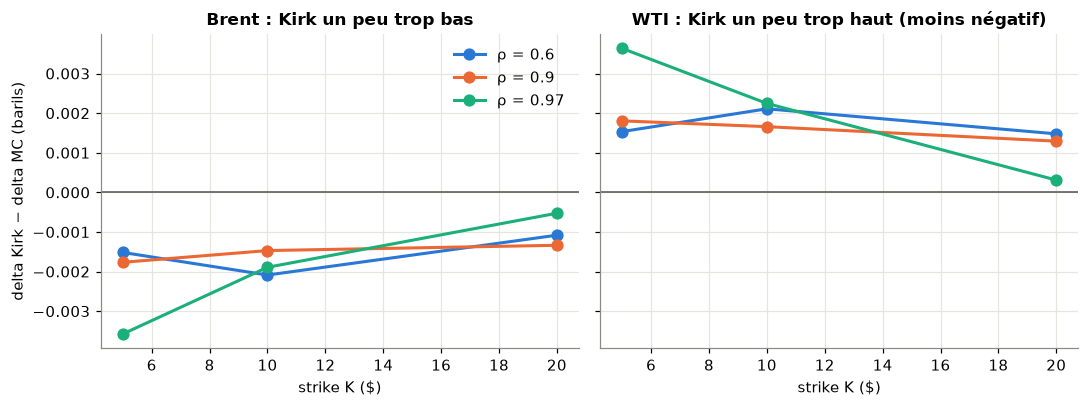

In [8]:
strikes_d = [5.0, 10.0, 20.0]
gap1, gap2 = {}, {}  # Kirk delta - MC delta, one list per rho
for rho_test in [0.6, 0.9, 0.97]:
    gap1[rho_test], gap2[rho_test] = [], []
    print(f"rho = {rho_test}")
    for K in strikes_d:
        runs = [mc_spread_deltas(S1_0, S2_0, K, T, r, sigma1, sigma2, rho_test, n_paths=2_000_000, seed=s)
                for s in range(101, 106)]  # 5 independent runs
        mc1 = np.mean([run[0] for run in runs])  # run = (delta1, delta2, std_err1, std_err2)
        mc2 = np.mean([run[1] for run in runs])
        kirk1, kirk2 = kirk_deltas(S1_0, S2_0, K, T, r, sigma1, sigma2, rho_test)
        gap1[rho_test].append(kirk1 - mc1)
        gap2[rho_test].append(kirk2 - mc2)
        print(f"   K = {K:4.1f} | Brent : MC {mc1:+.4f}, Kirk {kirk1:+.4f} (écart {kirk1 - mc1:+.4f}) "
              f"| WTI : MC {mc2:+.4f}, Kirk {kirk2:+.4f} (écart {kirk2 - mc2:+.4f})")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for rho_test, c in colors.items():
    axes[0].plot(strikes_d, gap1[rho_test], "o-", color=c, label=f"ρ = {rho_test}")
    axes[1].plot(strikes_d, gap2[rho_test], "o-", color=c)
for ax, name in [(axes[0], "Brent : Kirk un peu trop bas"), (axes[1], "WTI : Kirk un peu trop haut (moins négatif)")]:
    ax.axhline(0, color="#52514e", linewidth=1)
    ax.set_xlabel("strike K ($)")
    ax.set_title(name)
axes[0].set_ylabel("delta Kirk − delta MC (barils)")
axes[0].legend()
plt.tight_layout()
plt.show()

Les deltas de Kirk sont un peu trop petits en valeur absolue, sur les deux jambes : il manque 0,001 à 0,002 baril, et jusqu'à 0,0036 à $\rho = 0{,}97$ et $K = 5$. C'est un vrai biais (bien au-delà de 3 erreurs standard), mais il reste petit : moins de 1 % du delta près du spread du jour.

## 8. La couverture avec Kirk

Même expérience qu'à la section 4, mais à $K = 5$ : la banque vend l'option au prix de Kirk et la couvre chaque jour avec les deltas de Kirk, sur 1000 scénarios simulés par le GBM bivarié. On le fait pour $\rho = 0{,}6$ (cas de base) et $\rho = 0{,}9$ (plus proche de Brent/WTI). Environ 2 minutes 30 de calcul : 1000 scénarios × 252 jours × 4 prix de Kirk par jour.

rho = 0.6 | prime 9.05 $ | P&L moyen +0.025 $ (+/- 0.018) | écart-type 0.565 $ (6.2% de la prime) | pire 5 % -0.84 $


rho = 0.9 | prime 4.64 $ | P&L moyen +0.007 $ (+/- 0.009) | écart-type 0.271 $ (5.8% de la prime) | pire 5 % -0.45 $


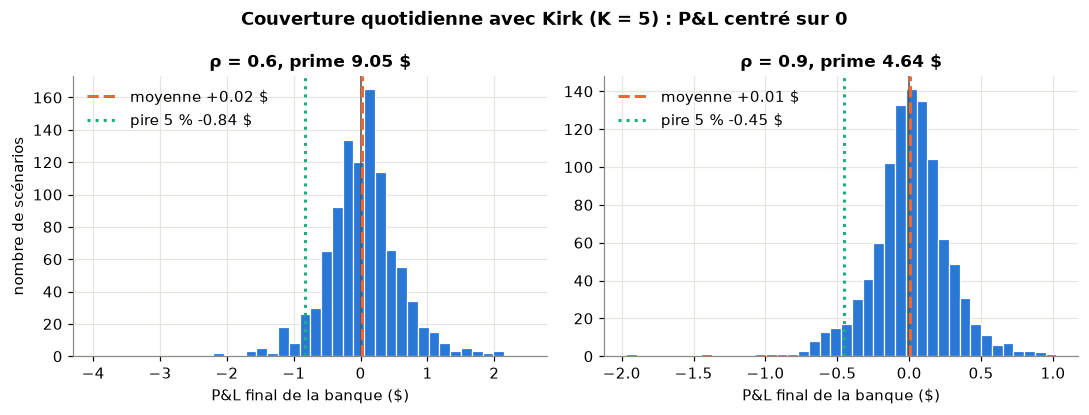

In [9]:
K = 5.0
pnl_kirk, prime_kirk = {}, {}
for rho_test in [0.6, 0.9]:
    paths1, paths2 = simulate_bivariate_gbm_paths(S1_0, S2_0, r, sigma1, sigma2, rho_test, obs_times, n_paths=1000)
    price0 = kirk_call(S1_0, S2_0, K, T, r, sigma1, sigma2, rho_test)
    pnl = delta_hedge_spread_pnl(
        paths1, paths2, T, r, price0,
        lambda S1, S2, t: kirk_deltas(S1, S2, K, t, r, sigma1, sigma2, rho_test),
        lambda S1T, S2T: spread_call_payoff(S1T, S2T, K),
    )
    print(f"rho = {rho_test} | prime {price0:.2f} $ | P&L moyen {pnl.mean():+.3f} $ "
          f"(+/- {pnl.std() / np.sqrt(len(pnl)):.3f}) | écart-type {pnl.std():.3f} $ ({pnl.std() / price0:.1%} de la prime) "
          f"| pire 5 % {np.quantile(pnl, 0.05):+.2f} $")
    pnl_kirk[rho_test], prime_kirk[rho_test] = pnl, price0

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, rho_test in zip(axes, [0.6, 0.9]):
    p = pnl_kirk[rho_test]
    ax.hist(p, bins=40, color=BLUE, edgecolor="white", linewidth=0.8)
    ax.axvline(0, color="#52514e", linewidth=1)
    ax.axvline(p.mean(), color=ORANGE, linestyle="--", label=f"moyenne {p.mean():+.2f} $")
    ax.axvline(np.quantile(p, 0.05), color=AQUA, linestyle=":", label=f"pire 5 % {np.quantile(p, 0.05):+.2f} $")
    ax.set_xlabel("P&L final de la banque ($)")
    ax.set_title(f"ρ = {rho_test}, prime {prime_kirk[rho_test]:.2f} $")
    ax.legend()
axes[0].set_ylabel("nombre de scénarios")
fig.suptitle("Couverture quotidienne avec Kirk (K = 5) : P&L centré sur 0", fontweight="bold")
plt.tight_layout()
plt.show()

Le P&L moyen reste proche de 0 (+0,02 \$ et +0,01 \$, moins de 1,5 erreur standard) : l'erreur de prix de Kirk et le petit biais de ses deltas ne se voient pas. L'écart-type, autour de 6 % de la prime, vient du rebalancement quotidien, comme pour Margrabe (4,7 % à $K = 0$, un autre produit, donc pas directement comparable). Dans le modèle GBM, couvrir avec Kirk marche donc aussi bien qu'avec une formule exacte.

## Ce qu'on retient

- À $K = 0$, MC et Margrabe sont d'accord sur le prix (moins de 2 erreurs standard) et sur les deltas (Brent +0,643, WTI −0,529). La couverture avec Margrabe donne un P&L moyen ≈ 0 (+0,02 \$) et un écart-type de 4,7 % de la prime.
- Margrabe et Kirk prennent moins d'un dixième de milliseconde, le MC quelques millisecondes (environ 5 ms ici, le chiffre bouge un peu d'une exécution à l'autre) : environ 60 fois plus.
- Kirk donne le prix pour $K \neq 0$ à moins de 1,2 centime près autour du spread du jour. Son erreur relative grandit loin hors de la monnaie quand $\rho$ est proche de 1, et il surestime un peu avec $K < 0$.
- Ses deltas (par bosses) sont à 0,001 à 0,004 baril des deltas MC. La couverture quotidienne avec Kirk à $K = 5$ donne un P&L moyen ≈ 0 et un écart-type d'environ 6 % de la prime.
- Sous le GBM, Kirk fait donc ce qu'on cherchait : prix et deltas pour $K \neq 0$, assez précis pour couvrir, environ 60 fois plus vite que le MC. Ce qu'il ne règle pas vient du modèle (prix négatifs, vol et corrélation qui changent) et de l'estimation de $\rho$.